In [15]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict, Literal
from dotenv import load_dotenv

In [2]:
load_dotenv()

model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [3]:
class QuadState(TypedDict):
    a: int
    b: int
    c: int

    equation: str
    discriminant: float
    result: str

In [13]:
def show_equation(state: QuadState) -> QuadState:
    equation = f"{state['a']}x² + {state['b']}x + {state['c']} = 0"
    return {'equation': equation}

def calculate_discriminant(state: QuadState) -> QuadState:
    discriminant = (state['b']**2) - (4*(state['a'])*(state['c']))
    return {'discriminant': discriminant}

def real_roots(state: QuadState):

    root1 = (-state["b"] + state["discriminant"]**0.5)/(2*state["a"])
    root2 = (-state["b"] - state["discriminant"]**0.5)/(2*state["a"])

    result = f'The roots are {root1} and {root2}'

    return {'result': result}

def repeated_roots(state: QuadState):

    root = (-state["b"])/(2*state["a"])

    result = f'Only repeating root is {root}'

    return {'result': result}

def no_real_roots(state: QuadState):

    result = f'No real roots'

    return {'result': result}

def check_condition(state: QuadState) -> Literal["real_roots", "repeated_roots", "no_real_roots"]:

    if state['discriminant'] > 0:
        return "real_roots"
    elif state['discriminant'] == 0:
        return "repeated_roots"
    else:
        return "no_real_roots"

In [17]:
graph = StateGraph(QuadState)

graph.add_node('show_equation', show_equation)
graph.add_node('calculate_discriminant', calculate_discriminant)
graph.add_node('real_roots', real_roots)
graph.add_node('repeated_roots', repeated_roots)
graph.add_node('no_real_roots', no_real_roots)
graph.add_node('check_condition', check_condition)

graph.add_edge(START, 'show_equation')
graph.add_edge('show_equation', 'calculate_discriminant')

graph.add_conditional_edges('calculate_discriminant', check_condition)

graph.add_edge('no_real_roots', END)
graph.add_edge('real_roots', END)
graph.add_edge('repeated_roots', END)

workflow = graph.compile()

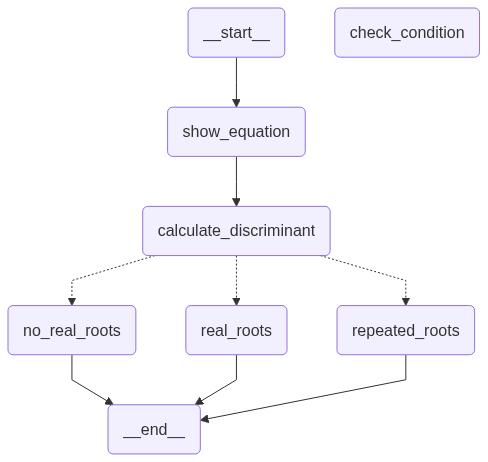

In [18]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [28]:
initial_state = {
    'a': 2,
    'b': 5,
    'c': 3
}
workflow.invoke(initial_state)

{'a': 2,
 'b': 5,
 'c': 3,
 'equation': '2x² + 5x + 3 = 0',
 'discriminant': 1,
 'result': 'The roots are -1.0 and -1.5'}